<a href="https://colab.research.google.com/github/Ariqq16/ML_2026/blob/main/JS10/JS10_TugasLab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

import seaborn as sns

print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.21.0


In [2]:
train_df = pd.read_csv(
    '/content/sample_data/mnist_train_small.csv',
    header=None
)

test_df = pd.read_csv(
    '/content/sample_data/mnist_test.csv',
    header=None
)

print("Ukuran data training:", train_df.shape)
print("Ukuran data testing:", test_df.shape)

display(train_df.head())

Ukuran data training: (20000, 785)
Ukuran data testing: (10000, 785)


,0,1,2,3,4,5,6,7,8,9,...,775,776,777,778,779,780,781,782,783,784
0,6,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,7,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [3]:
X = train_df.iloc[:, 1:].values
y = train_df.iloc[:, 0].values

X_test = test_df.iloc[:, 1:].values
y_test = test_df.iloc[:, 0].values

print("X:", X.shape)
print("y:", y.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X: (20000, 784)
y: (20000,)
X_test: (10000, 784)
y_test: (10000,)


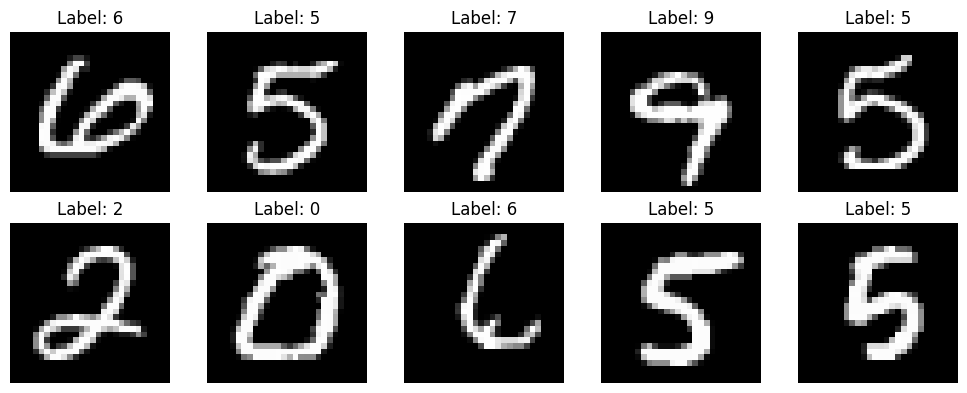

In [4]:
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X[i].reshape(28, 28), cmap='gray')
    plt.title(f'Label: {y[i]}')
    plt.axis('off')

plt.tight_layout()
plt.show()

In [5]:
X = X.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

print("Nilai minimum:", X.min())
print("Nilai maksimum:", X.max())

print("Normalisasi berhasil!")

Nilai minimum: 0.0
Nilai maksimum: 1.0
Normalisasi berhasil!


In [6]:
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Data training:", X_train.shape)
print("Data validation:", X_val.shape)
print("Data testing:", X_test.shape)

Data training: (16000, 784)
Data validation: (4000, 784)
Data testing: (10000, 784)


Membuat model ANN

In [7]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(784,)),

    tf.keras.layers.Dense(
        128,
        activation='relu'
    ),

    tf.keras.layers.Dense(
        64,
        activation='relu'
    ),

    tf.keras.layers.Dense(
        10,
        activation='softmax'
    )
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Model berhasil di-compile!")

Model berhasil di-compile!


In [9]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8805 - loss: 0.4170 - val_accuracy: 0.9273 - val_loss: 0.2415
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9503 - loss: 0.1695 - val_accuracy: 0.9465 - val_loss: 0.1781
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9678 - loss: 0.1118 - val_accuracy: 0.9532 - val_loss: 0.1635
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9761 - loss: 0.0792 - val_accuracy: 0.9563 - val_loss: 0.1457
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9818 - loss: 0.0597 - val_accuracy: 0.9542 - val_loss: 0.1561
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9881 - loss: 0.0425 - val_accuracy: 0.9592 - val_loss: 0.1444
Epoch 7/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9902 - loss: 0.0319 - val_accuracy: 0.9570 - val_loss: 0.1568
Epoch 8/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9924 - loss: 0.0254 - val_accuracy: 0.

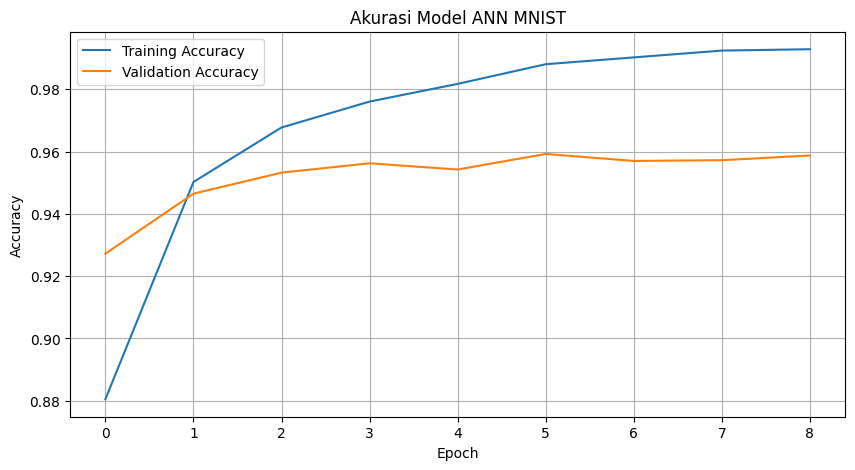

In [10]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title('Akurasi Model ANN MNIST')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()

plt.show()

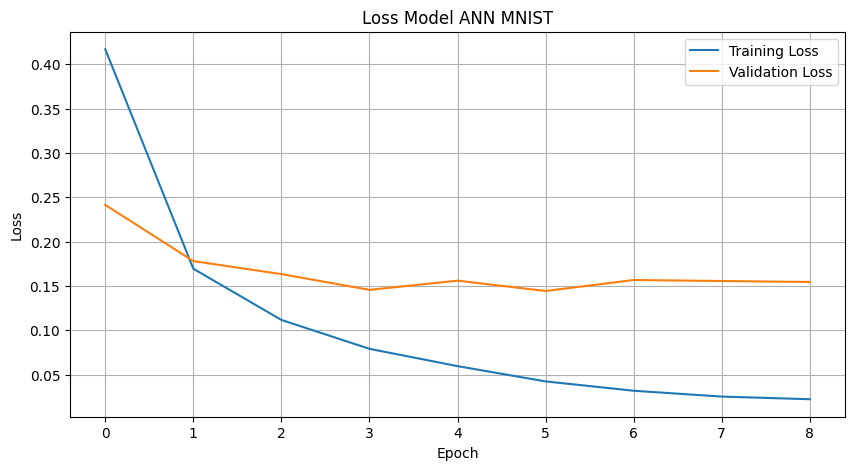

In [11]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.title('Loss Model ANN MNIST')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid()

plt.show()

In [12]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
print("Test Accuracy (%):", test_accuracy * 100)

Test Loss: 0.12333040684461594
Test Accuracy: 0.9664000272750854
Test Accuracy (%): 96.64000272750854


In [13]:
y_probability = model.predict(X_test)

y_pred = np.argmax(
    y_probability,
    axis=1
)

print("10 prediksi pertama:")
print(y_pred[:10])

print("\n10 label sebenarnya:")
print(y_test[:10])

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
10 prediksi pertama:
[7 2 1 0 4 1 4 9 6 9]

10 label sebenarnya:
[7 2 1 0 4 1 4 9 5 9]


In [14]:
print(classification_report(
    y_test,
    y_pred,
    digits=4
))

              precision    recall  f1-score   support

           0     0.9652    0.9908    0.9778       980
           1     0.9903    0.9885    0.9894      1135
           2     0.9561    0.9719    0.9640      1032
           3     0.9699    0.9564    0.9631      1010
           4     0.9665    0.9705    0.9685       982
           5     0.9501    0.9608    0.9554       892
           6     0.9727    0.9676    0.9702       958
           7     0.9566    0.9660    0.9613      1028
           8     0.9858    0.9261    0.9550       974
           9     0.9491    0.9613    0.9552      1009

    accuracy                         0.9664     10000
   macro avg     0.9662    0.9660    0.9660     10000
weighted avg     0.9666    0.9664    0.9664     10000



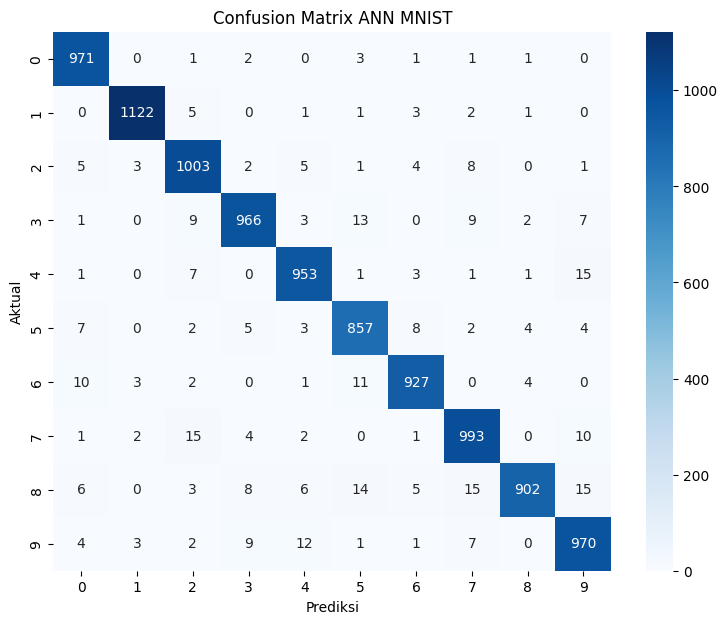

In [15]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title('Confusion Matrix ANN MNIST')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')

plt.show()

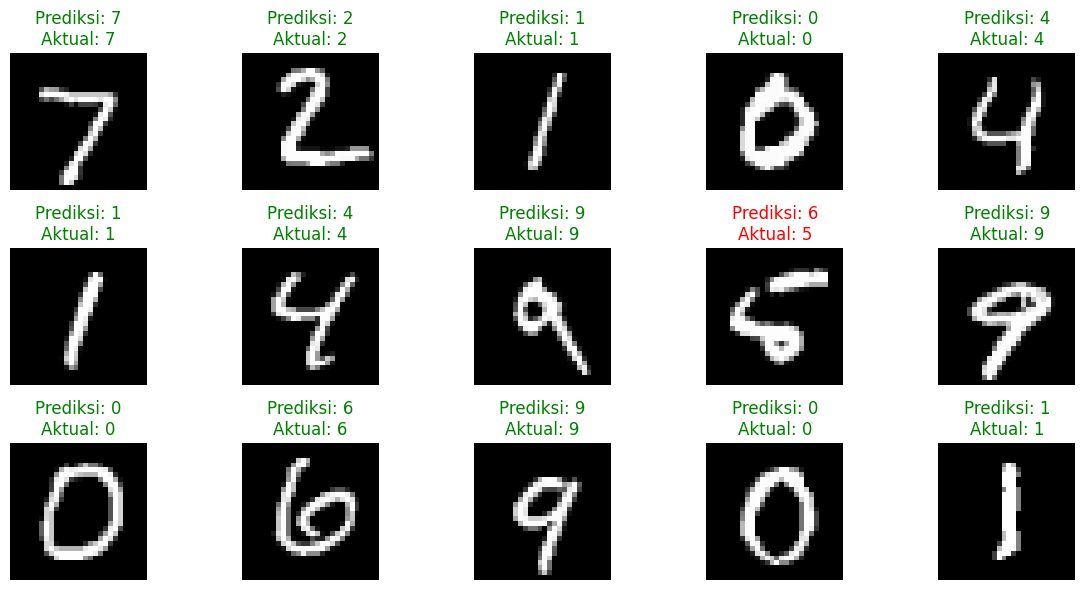

In [16]:
plt.figure(figsize=(12, 6))

for i in range(15):
    plt.subplot(3, 5, i + 1)

    plt.imshow(
        X_test[i].reshape(28, 28),
        cmap='gray'
    )

    warna = 'green' if y_pred[i] == y_test[i] else 'red'

    plt.title(
        f'Prediksi: {y_pred[i]}\nAktual: {y_test[i]}',
        color=warna
    )

    plt.axis('off')

plt.tight_layout()
plt.show()

In [17]:
def buat_model_ann(neurons):
    model = tf.keras.Sequential()

    model.add(tf.keras.layers.Input(shape=(784,)))

    for jumlah_neuron in neurons:
        model.add(
            tf.keras.layers.Dense(
                jumlah_neuron,
                activation='relu'
            )
        )

    model.add(
        tf.keras.layers.Dense(
            10,
            activation='softmax'
        )
    )

    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

In [18]:
konfigurasi = {
    'ANN 1': [64],
    'ANN 2': [128, 64],
    'ANN 3': [256, 128, 64]
}

hasil_eksperimen = []

for nama, neuron in konfigurasi.items():

    print(f"\nTraining {nama}: {neuron}")

    model_eksperimen = buat_model_ann(neuron)

    model_eksperimen.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=20,
        batch_size=32,
        callbacks=[
            tf.keras.callbacks.EarlyStopping(
                monitor='val_loss',
                patience=3,
                restore_best_weights=True
            )
        ],
        verbose=0
    )

    loss, accuracy = model_eksperimen.evaluate(
        X_test,
        y_test,
        verbose=0
    )

    hasil_eksperimen.append({
        'Model': nama,
        'Arsitektur': str(neuron),
        'Test Loss': loss,
        'Test Accuracy': accuracy
    })

    print("Test Accuracy:", accuracy)


Training ANN 1: [64]
Test Accuracy: 0.9609000086784363

Training ANN 2: [128, 64]
Test Accuracy: 0.9638000130653381

Training ANN 3: [256, 128, 64]
Test Accuracy: 0.9671000242233276


In [19]:
hasil_df = pd.DataFrame(hasil_eksperimen)

display(
    hasil_df.sort_values(
        by='Test Accuracy',
        ascending=False
    ).reset_index(drop=True)
)

,Model,Arsitektur,Test Loss,Test Accuracy
0,ANN 3,"[256, 128, 64]",0.118158,0.9671
1,ANN 2,"[128, 64]",0.117912,0.9638
2,ANN 1,[64],0.138084,0.9609


In [20]:
model.save('/content/model_ann_mnist.keras')

print("Model berhasil disimpan!")

Model berhasil disimpan!
